.. index:: Parallelization; MPI

# Distributed Parallel Simulations

We will run two of the examples already described in parallel to
demonstrate how little to no change is required to do so.

In [1]:
import subprocess
import sys
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

try:
    import mpi4py
except ImportError:
    print("Example requires an `mpi` installation - skipping")
    sys.exit(0)

oversub = ["--map-by", ":OVERSUBSCRIBE"] # allow oversubscription for this simple test

.. index:: Adaptation; Phase Field; MPI

## Parallel Crystal Growth Model

We now run the [crystal growth phase field example](crystal_nb.ipynb):

In [2]:
nprocs = 3
"""
subprocess.run(
    ["mpiexec", *oversub, "-n", str(nprocs), sys.executable, "crystal.py"],
    check=True,
)
"""

'\nsubprocess.run(\n    ["mpiexec", *oversub, "-n", str(nprocs), sys.executable, "crystal.py"],\n    check=True,\n)\n'

Each process produced a plot containing only part of the grid
at five different point in the simulation. Note how the call
`fem.gridAdapt(marker, u_h)` within the time loop does not only refine
and coarsen the grid but also leads to occasional repartitioning of
the grid to balance the load between the three processors.
We first use pvpython if available to generate figures showing the
combined grid and solution with the partitioning. Then we show the
individual domains - those figures were generated during the above call
to `crystal.py`:

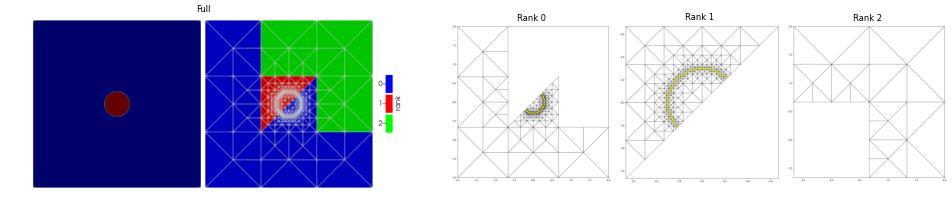

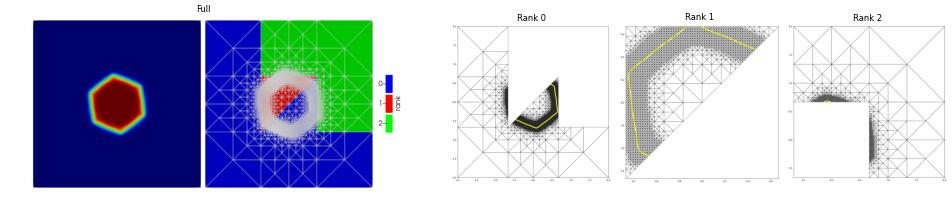

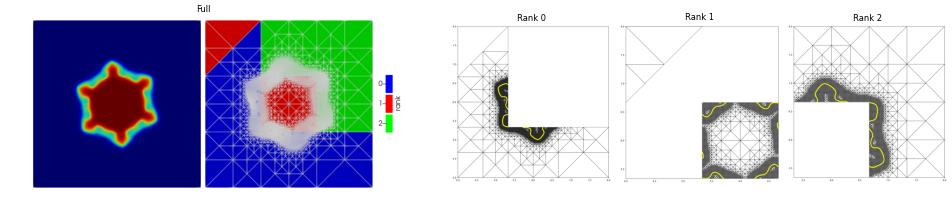

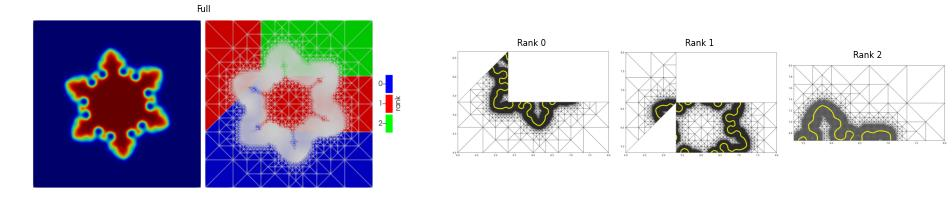

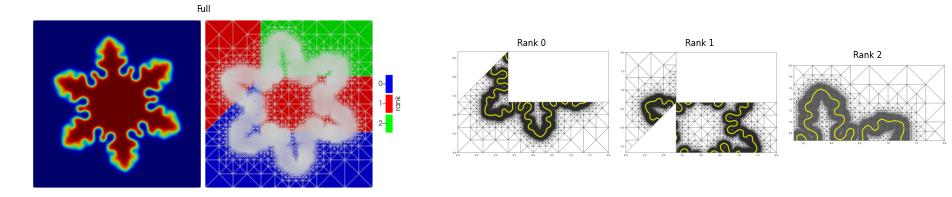

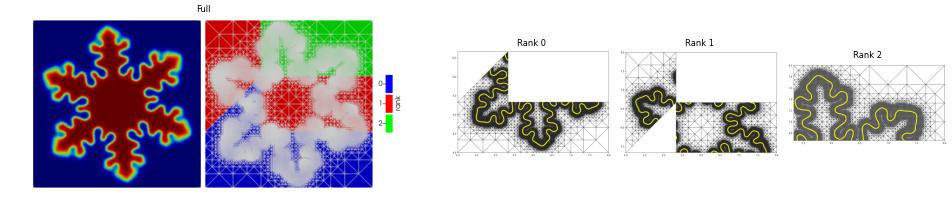

In [3]:
try: 
    for i in range(6):
        subprocess.run(['pvpython','pvcrystal.py', str(nprocs), str(i)],
                    stdout=subprocess.DEVNULL,
                    stderr=subprocess.DEVNULL,
                    check=True
        )
    figGenerated = True
except: # probably no pvpython available
    figGenerated = False
for i in range(6):
    fig, axes = plt.subplots(1, nprocs+1, figsize=(5*(nprocs+1), 4),
                             gridspec_kw={"width_ratios": [3] + [1] * nprocs})
    for rank, ax in enumerate(axes[1:]):
        image = mpimg.imread(f"crystal{rank}{nprocs}_{i}.png")
        ax.imshow(image)
        ax.set_title(f"Rank {rank}")
        ax.axis("off")
    if figGenerated:
        image = mpimg.imread(f"crystal{nprocs}_{i}.png")
        axes[0].imshow(image)
        axes[0].set_title(f"Full")
        axes[0].axis("off")
    fig.tight_layout()

.. index:: Equations; Wave Equation; MPI

## Parallel Wave Equation

We now run the [double slit domain wave example](wave_nb.ipynb)
on two processes with a distributed grid. Here we need to make a slight
adjustment to one part of the original code which is detailed below.
Note that this change could have been included in the serial version
without any issue. To keep the explanation simple there we decided
to include the change in the separate script.

In [4]:
nprocs = 2
subprocess.run(
    ["mpiexec", *oversub, "-n", str(nprocs), sys.executable, "wave_mpi.py"],
    check=True,
)

CompletedProcess(args=['mpiexec', '--map-by', ':OVERSUBSCRIBE', '-n', '2', '/home/dedner/dune-core/bin/python3', 'wave_mpi.py'], returncode=0)

Again each process produced a plot containing its part of the grid

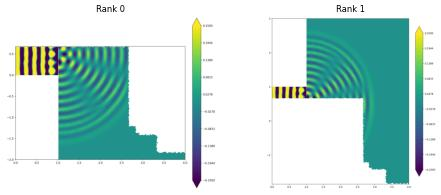

In [5]:
fig, axes = plt.subplots(1, nprocs, figsize=(5*nprocs, 4))
for rank, ax in enumerate(axes):
    image = mpimg.imread(f"wave_mpi{rank}.png")
    ax.imshow(image)
    ax.set_title(f"Rank {rank}")
    ax.axis("off")
fig.tight_layout()

Here is the code being run - note how almost no additional code is needed
compared to the [serial version](wave_nb.ipynb) with the exception
of the setup for the inverse lumped mass matrix

In [6]:
from IPython.display import Code, display
display(Code(filename="wave_mpi.py", language="python"))

from matplotlib import pyplot as plt
import numpy as np
from scipy.sparse import dia_matrix

import dune.common
import dune.fem as fem
from dune.grid import reader
from dune.alugrid import aluConformGrid as leafGridView
from dune.fem.space import lagrange as solutionSpace
from ufl import TrialFunction, TestFunction, SpatialCoordinate, grad, dot, dx
from dune.ufl import Constant, BoxDirichletBC, DirichletBC
from dune.fem.function import levelFunction, partitionFunction
from dune.fem.scheme import galerkin

T = 3
dt = 0.005
t = 0

domain = (reader.meshio, "wave_tank.msh")
gridView  = leafGridView( domain, dimgrid=2 )
gridView.hierarchicalGrid.loadBalance()
V = solutionSpace(gridView, order=1, storage="numpy")

u    = TrialFunction(V)
v    = TestFunction(V)
x    = SpatialCoordinate(V)

p      = V.interpolate(0,name="p")
phi    = V.interpolate(0,name="phi")

p_in = Constant(0.0, name="g")
bc   = DirichletBC(V, p_in, 1)

op        = galerkin([dot(grad(u),grad(v))*dx==0,bc])
S         = op.linear()
lapPhi    = V.interpolate(1,name="e")
lapPhiVec = lapPhi.as_numpy

lumping = galerkin(u*v*dx(metadata={"quadrature_rule":"lumped"})==0)
Mlumped = lumping.linear()

# 'Mlumped' is a diagonal matrix from which we need the inverse. To make
# this as efficient as possible we store the inverse in a scipy diagonal
# matrix. An issue is that the linear operator 'Mlumped' is additively
# distributed, so we first need to sum up diagonal entries shared over
# multiple processors. The linear operator itself does not provide a
# suitable communication method but we can interpret the diagonal entries
# as a discrete function and use the communication method there:
lumped = V.function(name="lump", dofVector=Mlumped.as_numpy.diagonal())
lumped.communicate()
N = lumped.size
Minv = dia_matrix(([dt/lumped.as_numpy],[0]),shape=(N,N) )

saveInterval = T/20
nextSaveTime = saveInterval
# vtk = gridView.sequencedVTK("wave", pointdata=[p,phi],
#                celldata=[levelFunction(gridView), partitionFunction(gridView)])
# vtk()

tmp = phi.copy()
while t <= T:
    phi.axpy(-dt/2, p)

    S(phi,tmp)
    p.as_numpy[:] += Minv*tmp.as_numpy[:]

    p_in.value = np.sin(2*np.pi*5*t)
    op.setConstraints(p)

    phi.axpy(-dt/2, p)

    if t > nextSaveTime-dt/4:
        # vtk()
        nextSaveTime += saveInterval
        # check for instabilities
        assert np.max(abs(p.as_numpy[:])) < 3

    # update time
    t += dt

# vtk()
fig = plt.figure(figsize=(10,10))
p.plot(gridLines=None, clim=[-0.25,0.25], figure=fig)
fig.savefig(f"wave_mpi{dune.common.comm.rank}.png", dpi=150, bbox_inches="tight")